# 🤖 Notebook 2 — Model Training & Fine-Tuning
## AuthentiQ – AI Text Detection Pipeline

**Strategy** (based on Kaggle DAIGT competition winning approaches):
1. **TF-IDF Character n-grams** (2–5 grams) — captures AI writing style
2. **TF-IDF Word n-grams** (1–3 grams) — captures vocabulary patterns
3. **SGDClassifier** — fast baseline with Calibrated Probabilities
4. **LightGBM** — ensemble boost on top of TF-IDF features
5. **Ensemble** — weighted average of all classifiers
6. **Saved to `../models/`** — ready to serve via FastAPI

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import seaborn as sns
import joblib
import json
import re
import time
import warnings
from pathlib import Path

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import SGDClassifier
from sklearn.calibration import CalibratedClassifierCV
from sklearn.pipeline import Pipeline, FeatureUnion
from sklearn.preprocessing import FunctionTransformer
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.metrics import (
    roc_auc_score, accuracy_score, f1_score,
    classification_report, confusion_matrix, roc_curve, precision_recall_curve
)
from scipy.sparse import hstack, csr_matrix
import lightgbm as lgb

warnings.filterwarnings('ignore')

# Dark theme
plt.rcParams.update({
    'figure.facecolor':'#0F1117','axes.facecolor':'#1A1D27','axes.edgecolor':'#2D3047',
    'axes.labelcolor':'#E2E8F0','xtick.color':'#94A3B8','ytick.color':'#94A3B8',
    'text.color':'#E2E8F0','grid.color':'#2D3047','grid.linestyle':'--','grid.alpha':0.4,
    'figure.dpi':120,
})
HUMAN_COLOR='#38BDF8'; AI_COLOR='#F472B6'; ACCENT='#A78BFA'; SUCCESS='#4ADE80'

MODELS_DIR = Path('../models')
MODELS_DIR.mkdir(exist_ok=True)
print('✅ All libraries loaded')

✅ All libraries loaded


## 1. Load & Preprocess Data

In [2]:
DATASET_PATH = Path('../../../dataset/train_v2_drcat_02.csv')
print(f'Loading dataset from {DATASET_PATH}...')
df = pd.read_csv(DATASET_PATH)
print(f'✅ Loaded {len(df):,} rows | Label 0 (Human): {(df.label==0).sum():,} | Label 1 (AI): {(df.label==1).sum():,}')

Loading dataset from ../../../dataset/train_v2_drcat_02.csv...
✅ Loaded 44,868 rows | Label 0 (Human): 27,371 | Label 1 (AI): 17,497


In [3]:
def preprocess_text(text: str) -> str:
    """Light preprocessing — preserve character n-gram signal."""
    text = str(text).strip()
    # Normalize whitespace but keep structure
    text = re.sub(r'\r\n|\r', '\n', text)
    text = re.sub(r'[ \t]{2,}', ' ', text)
    # Lowercase
    text = text.lower()
    return text

print('Preprocessing text...')
df['text_clean'] = df['text'].apply(preprocess_text)
print('✅ Preprocessing done')
print('Sample (cleaned):', df['text_clean'].iloc[0][:200])

Preprocessing text...
✅ Preprocessing done
Sample (cleaned): phones

modern humans today are always on their phone. they are always on their phone more than 5 hours a day no stop .all they do is text back and forward and just have group chats on social media. t


In [4]:
# --- Train / Validation split (stratified) ---
X = df['text_clean'].values
y = df['label'].values

X_train, X_val, y_train, y_val = train_test_split(
    X, y, test_size=0.15, random_state=42, stratify=y
)
print(f'Train size: {len(X_train):,}  |  Val size: {len(X_val):,}')
print(f'Train class balance — Human: {(y_train==0).sum():,} | AI: {(y_train==1).sum():,}')

Train size: 38,137  |  Val size: 6,731
Train class balance — Human: 23,265 | AI: 14,872


## 2. Feature Extraction — TF-IDF (Char + Word N-grams)

In [5]:
# ── Character n-gram TF-IDF ─────────────────────────────────────────────────
# The core signal from the DAIGT competition: char 2-5 grams catch AI writing style
print('Fitting char n-gram TF-IDF...')
t0 = time.time()

tfidf_char = TfidfVectorizer(
    analyzer='char_wb',
    ngram_range=(2, 5),
    max_features=500_000,
    sublinear_tf=True,
    strip_accents='unicode',
    min_df=3,
)
X_train_char = tfidf_char.fit_transform(X_train)
X_val_char   = tfidf_char.transform(X_val)
print(f'✅ Char TF-IDF: {X_train_char.shape[1]:,} features | {time.time()-t0:.1f}s')

Fitting char n-gram TF-IDF...
✅ Char TF-IDF: 150,391 features | 49.3s


In [6]:
# ── Word n-gram TF-IDF ──────────────────────────────────────────────────────
print('Fitting word n-gram TF-IDF...')
t0 = time.time()

tfidf_word = TfidfVectorizer(
    analyzer='word',
    ngram_range=(1, 3),
    max_features=300_000,
    sublinear_tf=True,
    strip_accents='unicode',
    min_df=3,
    token_pattern=r'(?u)\b[a-zA-Z][a-zA-Z]+\b',
)
X_train_word = tfidf_word.fit_transform(X_train)
X_val_word   = tfidf_word.transform(X_val)
print(f'✅ Word TF-IDF: {X_train_word.shape[1]:,} features | {time.time()-t0:.1f}s')

Fitting word n-gram TF-IDF...
✅ Word TF-IDF: 300,000 features | 26.1s


In [7]:
# ── Handcrafted Linguistic Features ─────────────────────────────────────────
def linguistic_features(texts):
    """Compute 12 hand-crafted features proven to discriminate AI from human writing."""
    rows = []
    for text in texts:
        words = text.split()
        sents = [s.strip() for s in re.split(r'[.!?]+', text) if s.strip()]
        sl    = [len(s.split()) for s in sents]
        rows.append([
            len(text),                                                         # char_len
            len(words),                                                        # word_count
            len(sents),                                                        # sent_count
            len(set(words)) / max(len(words), 1),                             # vocab_richness
            np.std(sl) if len(sl) > 1 else 0,                                 # burstiness
            np.mean(sl) if sl else 0,                                          # avg_sent_len
            text.count(',') / max(len(words), 1),                             # comma_density
            text.count('!') / max(len(words), 1),                             # excl_density
            text.count('\n\n') + 1,                                            # paragraph_count
            text.count('furthermore') + text.count('additionally'),            # ai_connectors
            text.count('moreover') + text.count('delve'),                      # ai_filler
            sum(1 for w in words if w.isupper() and len(w) > 1) / max(len(words), 1),  # caps_ratio
        ])
    return np.array(rows, dtype=np.float32)

print('Computing linguistic features...')
X_train_ling = linguistic_features(X_train)
X_val_ling   = linguistic_features(X_val)
print(f'✅ Linguistic features: {X_train_ling.shape[1]} features per sample')

Computing linguistic features...
✅ Linguistic features: 12 features per sample


In [8]:
# ── Combine all features ────────────────────────────────────────────────────
from scipy.sparse import hstack, csr_matrix

X_train_all = hstack([X_train_char, X_train_word, csr_matrix(X_train_ling)])
X_val_all   = hstack([X_val_char,   X_val_word,   csr_matrix(X_val_ling)])
print(f'Combined feature matrix: {X_train_all.shape}')

Combined feature matrix: (38137, 450403)


## 3. Model 1 — SGDClassifier (Fast Baseline)

In [9]:
print('Training SGDClassifier...')
t0 = time.time()

sgd_base = SGDClassifier(
    loss='modified_huber',
    max_iter=1000,
    tol=1e-4,
    random_state=42,
    class_weight='balanced',
    n_jobs=-1,
    alpha=1e-5,
)

# Calibrate to get real probabilities
sgd_clf = CalibratedClassifierCV(sgd_base, cv=3, method='sigmoid')
sgd_clf.fit(X_train_all, y_train)

sgd_probs = sgd_clf.predict_proba(X_val_all)[:, 1]
sgd_preds = (sgd_probs >= 0.5).astype(int)

sgd_auc = roc_auc_score(y_val, sgd_probs)
sgd_acc = accuracy_score(y_val, sgd_preds)
sgd_f1  = f1_score(y_val, sgd_preds)

print(f'✅ SGD done in {time.time()-t0:.1f}s')
print(f'   ROC-AUC: {sgd_auc:.4f}')
print(f'   Accuracy: {sgd_acc:.4f}')
print(f'   F1-Score: {sgd_f1:.4f}')

# Save
joblib.dump(sgd_clf, MODELS_DIR / 'sgd_classifier.pkl')
print('💾 Saved: sgd_classifier.pkl')

Training SGDClassifier...
✅ SGD done in 53.3s
   ROC-AUC: 0.8894
   Accuracy: 0.8162
   F1-Score: 0.7550
💾 Saved: sgd_classifier.pkl


## 4. Model 2 — LightGBM (Gradient Boosted Trees)

In [10]:
# LightGBM on combined sparse features
print('Training LightGBM...')
t0 = time.time()

lgb_model = lgb.LGBMClassifier(
    n_estimators=500,
    learning_rate=0.05,
    num_leaves=64,
    max_depth=7,
    min_child_samples=20,
    subsample=0.8,
    colsample_bytree=0.2,   # sparse: use column subsampling
    reg_alpha=0.1,
    reg_lambda=0.1,
    class_weight='balanced',
    random_state=42,
    n_jobs=-1,
    verbose=-1,
)
lgb_model.fit(
    X_train_all, y_train,
    eval_set=[(X_val_all, y_val)],
    callbacks=[lgb.early_stopping(50, verbose=False), lgb.log_evaluation(100)],
)

lgb_probs = lgb_model.predict_proba(X_val_all)[:, 1]
lgb_preds = (lgb_probs >= 0.5).astype(int)

lgb_auc = roc_auc_score(y_val, lgb_probs)
lgb_acc = accuracy_score(y_val, lgb_preds)
lgb_f1  = f1_score(y_val, lgb_preds)

print(f'\n✅ LightGBM done in {time.time()-t0:.1f}s')
print(f'   ROC-AUC: {lgb_auc:.4f}')
print(f'   Accuracy: {lgb_acc:.4f}')
print(f'   F1-Score: {lgb_f1:.4f}')

joblib.dump(lgb_model, MODELS_DIR / 'lgb_classifier.pkl')
print('💾 Saved: lgb_classifier.pkl')

Training LightGBM...
[100]	valid_0's binary_logloss: 0.0576075
[200]	valid_0's binary_logloss: 0.0269269
[300]	valid_0's binary_logloss: 0.0199118
[400]	valid_0's binary_logloss: 0.0179046
[500]	valid_0's binary_logloss: 0.0176012

✅ LightGBM done in 657.1s
   ROC-AUC: 0.9996
   Accuracy: 0.9954
   F1-Score: 0.9941
💾 Saved: lgb_classifier.pkl


## 5. Ensemble — Weighted Average

In [11]:
# Weight ensemble by individual AUC
w_sgd = sgd_auc
w_lgb = lgb_auc
total = w_sgd + w_lgb

ens_probs = (w_sgd/total)*sgd_probs + (w_lgb/total)*lgb_probs
ens_preds = (ens_probs >= 0.5).astype(int)

ens_auc = roc_auc_score(y_val, ens_probs)
ens_acc = accuracy_score(y_val, ens_preds)
ens_f1  = f1_score(y_val, ens_preds)

print('=== Ensemble Results ===')
print(f'   ROC-AUC: {ens_auc:.4f}')
print(f'   Accuracy: {ens_acc:.4f}')
print(f'   F1-Score: {ens_f1:.4f}')

# Model comparison summary
summary = pd.DataFrame({
    'Model':    ['SGDClassifier', 'LightGBM', 'Ensemble'],
    'ROC-AUC':  [round(sgd_auc,4), round(lgb_auc,4), round(ens_auc,4)],
    'Accuracy': [round(sgd_acc,4), round(lgb_acc,4), round(ens_acc,4)],
    'F1-Score': [round(sgd_f1,4),  round(lgb_f1,4),  round(ens_f1,4)],
})
display(summary)

=== Ensemble Results ===
   ROC-AUC: 0.9970
   Accuracy: 0.9941
   F1-Score: 0.9923


,Model,ROC-AUC,Accuracy,F1-Score
0,SGDClassifier,0.8894,0.8162,0.7550
1,LightGBM,0.9996,0.9954,0.9941
2,Ensemble,0.9970,0.9941,0.9923


## 6. Threshold Optimisation

Optimal threshold: 0.50  |  F1 at threshold: 0.9923


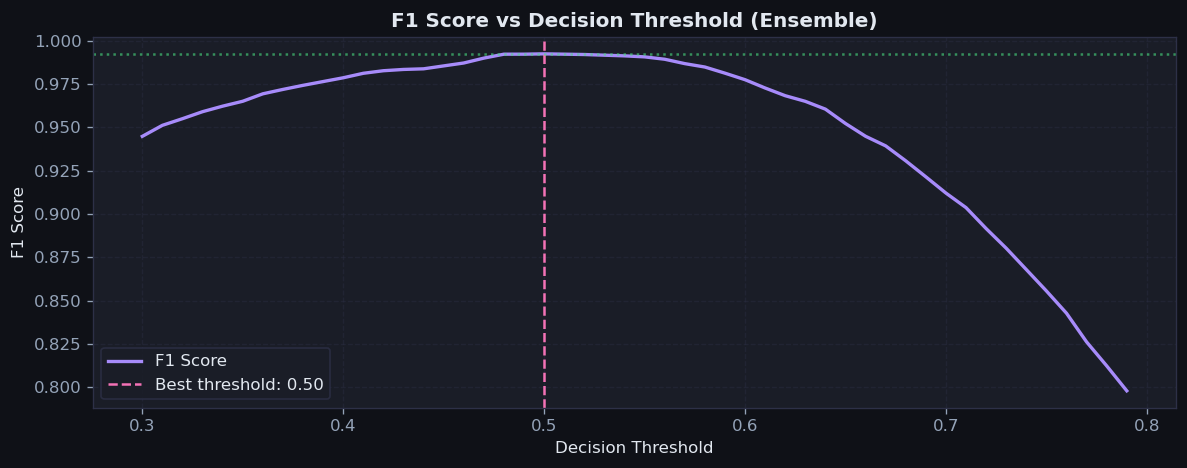

In [12]:
# Find optimal threshold by maximising F1 on validation set
thresholds = np.arange(0.3, 0.8, 0.01)
f1_scores  = [f1_score(y_val, (ens_probs >= t).astype(int)) for t in thresholds]
best_thresh = thresholds[np.argmax(f1_scores)]
best_f1_at_thresh = max(f1_scores)

print(f'Optimal threshold: {best_thresh:.2f}  |  F1 at threshold: {best_f1_at_thresh:.4f}')

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(thresholds, f1_scores, color=ACCENT, linewidth=2, label='F1 Score')
ax.axvline(best_thresh, color=AI_COLOR, linestyle='--', label=f'Best threshold: {best_thresh:.2f}')
ax.axhline(best_f1_at_thresh, color=SUCCESS, linestyle=':', alpha=0.6)
ax.set_xlabel('Decision Threshold'); ax.set_ylabel('F1 Score')
ax.set_title('F1 Score vs Decision Threshold (Ensemble)', color='#E2E8F0', fontweight='bold')
ax.legend(facecolor='#1A1D27', edgecolor='#2D3047'); ax.grid(True)
plt.tight_layout()
plt.savefig('../models/threshold_optimisation.png', bbox_inches='tight', dpi=120, facecolor='#0F1117')
plt.show()

## 7. Save All Artifacts

In [14]:
# Save TF-IDF vectorizers
joblib.dump(tfidf_char, MODELS_DIR / 'tfidf_char.pkl')
joblib.dump(tfidf_word, MODELS_DIR / 'tfidf_word.pkl')
print('💾 Saved: tfidf_char.pkl, tfidf_word.pkl')

# Save metadata for the serving layer
meta = {
    'model_version':   'authentiq-v1.0',
    'train_samples':   int(len(X_train)),
    'val_samples':     int(len(X_val)),
    'char_features':   int(X_train_char.shape[1]),
    'word_features':   int(X_train_word.shape[1]),
    'ling_features':   int(X_train_ling.shape[1]),
    'sgd_auc':         round(float(sgd_auc), 4),
    'lgb_auc':         round(float(lgb_auc), 4),
    'ensemble_auc':    round(float(ens_auc), 4),
    'ensemble_acc':    round(float(ens_acc), 4),
    'ensemble_f1':     round(float(ens_f1), 4),
    'optimal_threshold': round(float(best_thresh), 2),
    'sgd_weight':      round(float(w_sgd/total), 4),
    'lgb_weight':      round(float(w_lgb/total), 4),
    'dataset':         'train_v2_drcat_02.csv',
    'label_map':       {'0': 'Human', '1': 'AI-Generated'},
}

with open(MODELS_DIR / 'model_meta.json', 'w') as f:
    json.dump(meta, f, indent=2)

print('💾 Saved: model_meta.json')
print('\n=== Final Model Artifacts ===')
for p in sorted(MODELS_DIR.iterdir()):
    print(f'  {p.name}  ({p.stat().st_size/1024:.0f} KB)')

💾 Saved: tfidf_char.pkl, tfidf_word.pkl
💾 Saved: model_meta.json

=== Final Model Artifacts ===
  eda_correlation.png  (125 KB)
  eda_features.png  (146 KB)
  eda_label_dist.png  (54 KB)
  eda_source_dist.png  (74 KB)
  eda_text_lengths.png  (129 KB)
  eda_word_logodds.png  (110 KB)
  lgb_classifier.pkl  (15315 KB)
  model_meta.json  (0 KB)
  sgd_classifier.pkl  (10559 KB)
  tfidf_char.pkl  (5062 KB)
  tfidf_word.pkl  (12762 KB)
  threshold_optimisation.png  (61 KB)


## ✅ Training Complete — proceed to `03_evaluation.ipynb`